In [10]:
import sys
print(sys.executable)

D:\Навчання\3kurs\kursova\src\Services\RepairPrediction\.venv\Scripts\python.exe


# Прогноз тривалості ремонту
Порівнюємо **Ridge**, **випадковий ліс**, **дерево рішень**, **градієнтний бустинг** і базовий прогноз за медіаною. Критерій вибору — **MAE на validation** (середня абсолютна похибка в хвилинах, менше — краще). Для регресії не використовуємо accuracy.

Запусти комірки згори вниз. Ноутбук читає CSV і навчає моделі в пам'яті, не змінюючи моделі сайту.

In [11]:
from pathlib import Path
import hashlib
import sys

import matplotlib.pyplot as plt
import numpy as np
import sklearn
from IPython.display import Markdown, display
from sklearn.base import clone
from sklearn.feature_extraction import DictVectorizer
from sklearn.model_selection import ParameterGrid
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

cwd = Path.cwd().resolve()
repo = next((p for p in (cwd, *cwd.parents)
             if (p / "src/Services/RepairPrediction/dataset.py").is_file()), None)
if repo is None:
    raise RuntimeError("Відкрий ноутбук усередині репозиторію або запусти Jupyter з його кореня.")
sys.path.insert(0, str(repo / "src/Services/RepairPrediction"))

# Заміни на Path(r"D:/шлях/до/файлу.csv"), якщо CSV лежить деінде.
DATA_PATH = repo / "artifacts/ml/repair-orders.csv"
print("CSV:", DATA_PATH)
print("SHA-256:", hashlib.sha256(DATA_PATH.read_bytes()).hexdigest())
print("scikit-learn:", sklearn.__version__)

from dataset import chronological_split, load_repairs

def show_table(headers, rows):
    lines = [
        "| " + " | ".join(headers) + " |",
        "| " + " | ".join(["---"] * len(headers)) + " |",
    ]
    lines.extend("| " + " | ".join(map(str, row)) + " |" for row in rows)
    display(Markdown("\n".join(lines)))

def select_on_validation(models, train_x, train_y, val_x, val_y, score, predict):
    best = {}
    trials = []
    for name, (estimator, grid) in models.items():
        for params in ParameterGrid(grid):
            fitted = clone(estimator).set_params(**params).fit(train_x, train_y)
            loss = score(val_y, predict(fitted, val_x))
            trials.append((name, params, loss))
            if name not in best or loss < best[name][1]:
                best[name] = params, loss
    return best, trials

def split_overview(train, validation, test):
    show_table(["Вибірка", "Кількість", "Від", "До"], [
        (name, len(rows), rows[0].appointment.date(), rows[-1].appointment.date())
        for name, rows in (("Train", train), ("Validation", validation), ("Test", test))
    ])

CSV: D:\Навчання\3kurs\kursova\artifacts\ml\repair-orders.csv
SHA-256: ebc7db50a8df52b2de258b9868825a6f48839584d31a2516f6ca0de8096957d5
scikit-learn: 1.7.2


## 1. Дані та моделі
Використовуємо ті самі ознаки, що й сервіс: авто, пробіг, майстер, місцевий час запису та послуги. Фактична тривалість — ціль, а не ознака. Найстаріші записи йдуть у навчання, наступні — у validation, найновіші — у test (приблизно 70/15/15). Записи одного дня не розділяємо.

In [12]:
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.tree import DecisionTreeRegressor

from train_duration import xy

train, validation, test = chronological_split(load_repairs(DATA_PATH))
split_overview(train, validation, test)
train_x, train_y = xy(train)
val_x, val_y = xy(validation)

baseline = "Медіана"
models = {
    baseline: (DummyRegressor(strategy="median"), {}),
    "Ridge": (
        make_pipeline(DictVectorizer(sparse=False), StandardScaler(), Ridge()),
        {"ridge__alpha": [0.1, 1.0, 10.0, 100.0]},
    ),
    "Random Forest": (
        make_pipeline(DictVectorizer(sparse=False),
                      RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=1)),
        {"randomforestregressor__max_depth": [6, 12, None],
         "randomforestregressor__min_samples_leaf": [1, 3, 8]},
    ),
    "Дерево рішень": (
        make_pipeline(DictVectorizer(sparse=False), DecisionTreeRegressor(random_state=42)),
        {"decisiontreeregressor__max_depth": [2, 4, 6, 8],
         "decisiontreeregressor__min_samples_leaf": [5, 10, 20]},
    ),
    "Градієнтний бустинг": (
        make_pipeline(DictVectorizer(sparse=False), GradientBoostingRegressor(random_state=42)),
        {"gradientboostingregressor__max_depth": [1, 2, 3],
         "gradientboostingregressor__n_estimators": [50, 100, 200],
         "gradientboostingregressor__learning_rate": [0.03, 0.1],
         "gradientboostingregressor__min_samples_leaf": [5, 15]},
    ),
}

def predict(model, features):
    return model.predict(features)

| Вибірка | Кількість | Від | До |
| --- | --- | --- | --- |
| Train | 700 | 2026-04-15 | 2026-09-01 |
| Validation | 147 | 2026-09-02 | 2026-09-30 |
| Test | 153 | 2026-10-01 | 2026-10-30 |

## 2. Підбір параметрів
Кожну конфігурацію навчаємо тільки на train. Переможця серед ML-моделей обираємо за validation та окремо перевіряємо, чи він кращий за медіану.

In [13]:
best, trials = select_on_validation(
    models, train_x, train_y, val_x, val_y, mean_absolute_error, predict,
)
winner = min((name for name in models if name != baseline), key=lambda name: best[name][1])
print(f"Обрана модель: {winner}; параметри: {best[winner][0]}")
print("Краща за базову на validation:", "так" if best[winner][1] < best[baseline][1] else "ні")
show_table(["Модель", "Найкращі параметри", "Похибка на validation"], [
    (name, f"`{params}`", f"{loss:.4f}")
    for name, (params, loss) in sorted(best.items(), key=lambda item: item[1][1])
])
display(Markdown("**Усі перевірені конфігурації**"))
show_table(["Модель", "Перевірені параметри", "Похибка на validation"], [
    (name, f"`{params}`", f"{loss:.4f}") for name, params, loss in trials
])

Обрана модель: Ridge; параметри: {'ridge__alpha': 0.1}
Краща за базову на validation: так


| Модель | Найкращі параметри | Похибка на validation |
| --- | --- | --- |
| Ridge | `{'ridge__alpha': 0.1}` | 24.2319 |
| Градієнтний бустинг | `{'gradientboostingregressor__learning_rate': 0.1, 'gradientboostingregressor__max_depth': 3, 'gradientboostingregressor__min_samples_leaf': 5, 'gradientboostingregressor__n_estimators': 200}` | 24.7835 |
| Random Forest | `{'randomforestregressor__max_depth': None, 'randomforestregressor__min_samples_leaf': 3}` | 26.7968 |
| Дерево рішень | `{'decisiontreeregressor__max_depth': 8, 'decisiontreeregressor__min_samples_leaf': 5}` | 29.7298 |
| Медіана | `{}` | 61.8912 |

**Усі перевірені конфігурації**

| Модель | Перевірені параметри | Похибка на validation |
| --- | --- | --- |
| Медіана | `{}` | 61.8912 |
| Ridge | `{'ridge__alpha': 0.1}` | 24.2319 |
| Ridge | `{'ridge__alpha': 1.0}` | 24.2422 |
| Ridge | `{'ridge__alpha': 10.0}` | 24.3696 |
| Ridge | `{'ridge__alpha': 100.0}` | 26.3740 |
| Random Forest | `{'randomforestregressor__max_depth': 6, 'randomforestregressor__min_samples_leaf': 1}` | 31.3931 |
| Random Forest | `{'randomforestregressor__max_depth': 6, 'randomforestregressor__min_samples_leaf': 3}` | 30.8325 |
| Random Forest | `{'randomforestregressor__max_depth': 6, 'randomforestregressor__min_samples_leaf': 8}` | 32.6104 |
| Random Forest | `{'randomforestregressor__max_depth': 12, 'randomforestregressor__min_samples_leaf': 1}` | 28.5109 |
| Random Forest | `{'randomforestregressor__max_depth': 12, 'randomforestregressor__min_samples_leaf': 3}` | 27.3227 |
| Random Forest | `{'randomforestregressor__max_depth': 12, 'randomforestregressor__min_samples_leaf': 8}` | 29.6828 |
| Random Forest | `{'randomforestregressor__max_depth': None, 'randomforestregressor__min_samples_leaf': 1}` | 28.4367 |
| Random Forest | `{'randomforestregressor__max_depth': None, 'randomforestregressor__min_samples_leaf': 3}` | 26.7968 |
| Random Forest | `{'randomforestregressor__max_depth': None, 'randomforestregressor__min_samples_leaf': 8}` | 29.1569 |
| Дерево рішень | `{'decisiontreeregressor__max_depth': 2, 'decisiontreeregressor__min_samples_leaf': 5}` | 49.9300 |
| Дерево рішень | `{'decisiontreeregressor__max_depth': 2, 'decisiontreeregressor__min_samples_leaf': 10}` | 49.9300 |
| Дерево рішень | `{'decisiontreeregressor__max_depth': 2, 'decisiontreeregressor__min_samples_leaf': 20}` | 52.5831 |
| Дерево рішень | `{'decisiontreeregressor__max_depth': 4, 'decisiontreeregressor__min_samples_leaf': 5}` | 36.8834 |
| Дерево рішень | `{'decisiontreeregressor__max_depth': 4, 'decisiontreeregressor__min_samples_leaf': 10}` | 36.7718 |
| Дерево рішень | `{'decisiontreeregressor__max_depth': 4, 'decisiontreeregressor__min_samples_leaf': 20}` | 49.6369 |
| Дерево рішень | `{'decisiontreeregressor__max_depth': 6, 'decisiontreeregressor__min_samples_leaf': 5}` | 32.2932 |
| Дерево рішень | `{'decisiontreeregressor__max_depth': 6, 'decisiontreeregressor__min_samples_leaf': 10}` | 31.9040 |
| Дерево рішень | `{'decisiontreeregressor__max_depth': 6, 'decisiontreeregressor__min_samples_leaf': 20}` | 49.2381 |
| Дерево рішень | `{'decisiontreeregressor__max_depth': 8, 'decisiontreeregressor__min_samples_leaf': 5}` | 29.7298 |
| Дерево рішень | `{'decisiontreeregressor__max_depth': 8, 'decisiontreeregressor__min_samples_leaf': 10}` | 29.7890 |
| Дерево рішень | `{'decisiontreeregressor__max_depth': 8, 'decisiontreeregressor__min_samples_leaf': 20}` | 48.5868 |
| Градієнтний бустинг | `{'gradientboostingregressor__learning_rate': 0.03, 'gradientboostingregressor__max_depth': 1, 'gradientboostingregressor__min_samples_leaf': 5, 'gradientboostingregressor__n_estimators': 50}` | 51.9828 |
| Градієнтний бустинг | `{'gradientboostingregressor__learning_rate': 0.03, 'gradientboostingregressor__max_depth': 1, 'gradientboostingregressor__min_samples_leaf': 5, 'gradientboostingregressor__n_estimators': 100}` | 44.7369 |
| Градієнтний бустинг | `{'gradientboostingregressor__learning_rate': 0.03, 'gradientboostingregressor__max_depth': 1, 'gradientboostingregressor__min_samples_leaf': 5, 'gradientboostingregressor__n_estimators': 200}` | 37.7146 |
| Градієнтний бустинг | `{'gradientboostingregressor__learning_rate': 0.03, 'gradientboostingregressor__max_depth': 1, 'gradientboostingregressor__min_samples_leaf': 15, 'gradientboostingregressor__n_estimators': 50}` | 51.9828 |
| Градієнтний бустинг | `{'gradientboostingregressor__learning_rate': 0.03, 'gradientboostingregressor__max_depth': 1, 'gradientboostingregressor__min_samples_leaf': 15, 'gradientboostingregressor__n_estimators': 100}` | 44.7369 |
| Градієнтний бустинг | `{'gradientboostingregressor__learning_rate': 0.03, 'gradientboostingregressor__max_depth': 1, 'gradientboostingregressor__min_samples_leaf': 15, 'gradientboostingregressor__n_estimators': 200}` | 37.7146 |
| Градієнтний бустинг | `{'gradientboostingregressor__learning_rate': 0.03, 'gradientboostingregressor__max_depth': 2, 'gradientboostingregressor__min_samples_leaf': 5, 'gradientboostingregressor__n_estimators': 50}` | 44.9782 |
| Градієнтний бустинг | `{'gradientboostingregressor__learning_rate': 0.03, 'gradientboostingregressor__max_depth': 2, 'gradientboostingregressor__min_samples_leaf': 5, 'gradientboostingregressor__n_estimators': 100}` | 37.2054 |
| Градієнтний бустинг | `{'gradientboostingregressor__learning_rate': 0.03, 'gradientboostingregressor__max_depth': 2, 'gradientboostingregressor__min_samples_leaf': 5, 'gradientboostingregressor__n_estimators': 200}` | 30.5638 |
| Градієнтний бустинг | `{'gradientboostingregressor__learning_rate': 0.03, 'gradientboostingregressor__max_depth': 2, 'gradientboostingregressor__min_samples_leaf': 15, 'gradientboostingregressor__n_estimators': 50}` | 45.3289 |
| Градієнтний бустинг | `{'gradientboostingregressor__learning_rate': 0.03, 'gradientboostingregressor__max_depth': 2, 'gradientboostingregressor__min_samples_leaf': 15, 'gradientboostingregressor__n_estimators': 100}` | 37.4988 |
| Градієнтний бустинг | `{'gradientboostingregressor__learning_rate': 0.03, 'gradientboostingregressor__max_depth': 2, 'gradientboostingregressor__min_samples_leaf': 15, 'gradientboostingregressor__n_estimators': 200}` | 30.7889 |
| Градієнтний бустинг | `{'gradientboostingregressor__learning_rate': 0.03, 'gradientboostingregressor__max_depth': 3, 'gradientboostingregressor__min_samples_leaf': 5, 'gradientboostingregressor__n_estimators': 50}` | 40.3330 |
| Градієнтний бустинг | `{'gradientboostingregressor__learning_rate': 0.03, 'gradientboostingregressor__max_depth': 3, 'gradientboostingregressor__min_samples_leaf': 5, 'gradientboostingregressor__n_estimators': 100}` | 32.8276 |
| Градієнтний бустинг | `{'gradientboostingregressor__learning_rate': 0.03, 'gradientboostingregressor__max_depth': 3, 'gradientboostingregressor__min_samples_leaf': 5, 'gradientboostingregressor__n_estimators': 200}` | 27.9716 |
| Градієнтний бустинг | `{'gradientboostingregressor__learning_rate': 0.03, 'gradientboostingregressor__max_depth': 3, 'gradientboostingregressor__min_samples_leaf': 15, 'gradientboostingregressor__n_estimators': 50}` | 42.6485 |
| Градієнтний бустинг | `{'gradientboostingregressor__learning_rate': 0.03, 'gradientboostingregressor__max_depth': 3, 'gradientboostingregressor__min_samples_leaf': 15, 'gradientboostingregressor__n_estimators': 100}` | 34.7321 |
| Градієнтний бустинг | `{'gradientboostingregressor__learning_rate': 0.03, 'gradientboostingregressor__max_depth': 3, 'gradientboostingregressor__min_samples_leaf': 15, 'gradientboostingregressor__n_estimators': 200}` | 29.7682 |
| Градієнтний бустинг | `{'gradientboostingregressor__learning_rate': 0.1, 'gradientboostingregressor__max_depth': 1, 'gradientboostingregressor__min_samples_leaf': 5, 'gradientboostingregressor__n_estimators': 50}` | 39.1264 |
| Градієнтний бустинг | `{'gradientboostingregressor__learning_rate': 0.1, 'gradientboostingregressor__max_depth': 1, 'gradientboostingregressor__min_samples_leaf': 5, 'gradientboostingregressor__n_estimators': 100}` | 32.2546 |
| Градієнтний бустинг | `{'gradientboostingregressor__learning_rate': 0.1, 'gradientboostingregressor__max_depth': 1, 'gradientboostingregressor__min_samples_leaf': 5, 'gradientboostingregressor__n_estimators': 200}` | 27.8465 |
| Градієнтний бустинг | `{'gradientboostingregressor__learning_rate': 0.1, 'gradientboostingregressor__max_depth': 1, 'gradientboostingregressor__min_samples_leaf': 15, 'gradientboostingregressor__n_estimators': 50}` | 39.1264 |
| Градієнтний бустинг | `{'gradientboostingregressor__learning_rate': 0.1, 'gradientboostingregressor__max_depth': 1, 'gradientboostingregressor__min_samples_leaf': 15, 'gradientboostingregressor__n_estimators': 100}` | 32.2546 |
| Градієнтний бустинг | `{'gradientboostingregressor__learning_rate': 0.1, 'gradientboostingregressor__max_depth': 1, 'gradientboostingregressor__min_samples_leaf': 15, 'gradientboostingregressor__n_estimators': 200}` | 27.8465 |
| Градієнтний бустинг | `{'gradientboostingregressor__learning_rate': 0.1, 'gradientboostingregressor__max_depth': 2, 'gradientboostingregressor__min_samples_leaf': 5, 'gradientboostingregressor__n_estimators': 50}` | 31.8447 |
| Градієнтний бустинг | `{'gradientboostingregressor__learning_rate': 0.1, 'gradientboostingregressor__max_depth': 2, 'gradientboostingregressor__min_samples_leaf': 5, 'gradientboostingregressor__n_estimators': 100}` | 27.9274 |
| Градієнтний бустинг | `{'gradientboostingregressor__learning_rate': 0.1, 'gradientboostingregressor__max_depth': 2, 'gradientboostingregressor__min_samples_leaf': 5, 'gradientboostingregressor__n_estimators': 200}` | 25.7230 |
| Градієнтний бустинг | `{'gradientboostingregressor__learning_rate': 0.1, 'gradientboostingregressor__max_depth': 2, 'gradientboostingregressor__min_samples_leaf': 15, 'gradientboostingregressor__n_estimators': 50}` | 31.9445 |
| Градієнтний бустинг | `{'gradientboostingregressor__learning_rate': 0.1, 'gradientboostingregressor__max_depth': 2, 'gradientboostingregressor__min_samples_leaf': 15, 'gradientboostingregressor__n_estimators': 100}` | 27.9408 |
| Градієнтний бустинг | `{'gradientboostingregressor__learning_rate': 0.1, 'gradientboostingregressor__max_depth': 2, 'gradientboostingregressor__min_samples_leaf': 15, 'gradientboostingregressor__n_estimators': 200}` | 25.8019 |
| Градієнтний бустинг | `{'gradientboostingregressor__learning_rate': 0.1, 'gradientboostingregressor__max_depth': 3, 'gradientboostingregressor__min_samples_leaf': 5, 'gradientboostingregressor__n_estimators': 50}` | 28.7928 |
| Градієнтний бустинг | `{'gradientboostingregressor__learning_rate': 0.1, 'gradientboostingregressor__max_depth': 3, 'gradientboostingregressor__min_samples_leaf': 5, 'gradientboostingregressor__n_estimators': 100}` | 26.2315 |
| Градієнтний бустинг | `{'gradientboostingregressor__learning_rate': 0.1, 'gradientboostingregressor__max_depth': 3, 'gradientboostingregressor__min_samples_leaf': 5, 'gradientboostingregressor__n_estimators': 200}` | 24.7835 |
| Градієнтний бустинг | `{'gradientboostingregressor__learning_rate': 0.1, 'gradientboostingregressor__max_depth': 3, 'gradientboostingregressor__min_samples_leaf': 15, 'gradientboostingregressor__n_estimators': 50}` | 30.4193 |
| Градієнтний бустинг | `{'gradientboostingregressor__learning_rate': 0.1, 'gradientboostingregressor__max_depth': 3, 'gradientboostingregressor__min_samples_leaf': 15, 'gradientboostingregressor__n_estimators': 100}` | 27.4886 |
| Градієнтний бустинг | `{'gradientboostingregressor__learning_rate': 0.1, 'gradientboostingregressor__max_depth': 3, 'gradientboostingregressor__min_samples_leaf': 15, 'gradientboostingregressor__n_estimators': 200}` | 25.9121 |

## 3. Фінальна оцінка
Зафіксовані конфігурації перенавчаємо на train + validation. Test використовується лише для оцінки. RMSE сильніше штрафує великі помилки; R² — додаткова метрика, яка може бути від’ємною.

In [14]:
test_x, test_y = xy(test)
test_y = np.asarray(test_y)
predictions = {
    name: predict(clone(estimator).set_params(**best[name][0]).fit(train_x + val_x, train_y + val_y), test_x)
    for name, (estimator, _) in models.items()
}
test_mae = {name: mean_absolute_error(test_y, pred) for name, pred in predictions.items()}
show_table(["Модель", "Validation MAE, хв", "Test MAE, хв", "Test RMSE, хв", "Test R²"], [
    (name, f"{best[name][1]:.2f}", f"{test_mae[name]:.2f}",
     f"{root_mean_squared_error(test_y, pred):.2f}",
     f"{r2_score(test_y, pred):.3f}" if len(test_y) >= 2 else "—")
    for name, pred in predictions.items()
])

| Модель | Validation MAE, хв | Test MAE, хв | Test RMSE, хв | Test R² |
| --- | --- | --- | --- | --- |
| Медіана | 61.89 | 67.67 | 92.21 | -0.103 |
| Ridge | 24.23 | 23.39 | 31.32 | 0.873 |
| Random Forest | 26.80 | 25.02 | 33.58 | 0.854 |
| Дерево рішень | 29.73 | 31.15 | 40.46 | 0.788 |
| Градієнтний бустинг | 24.78 | 26.98 | 34.84 | 0.843 |

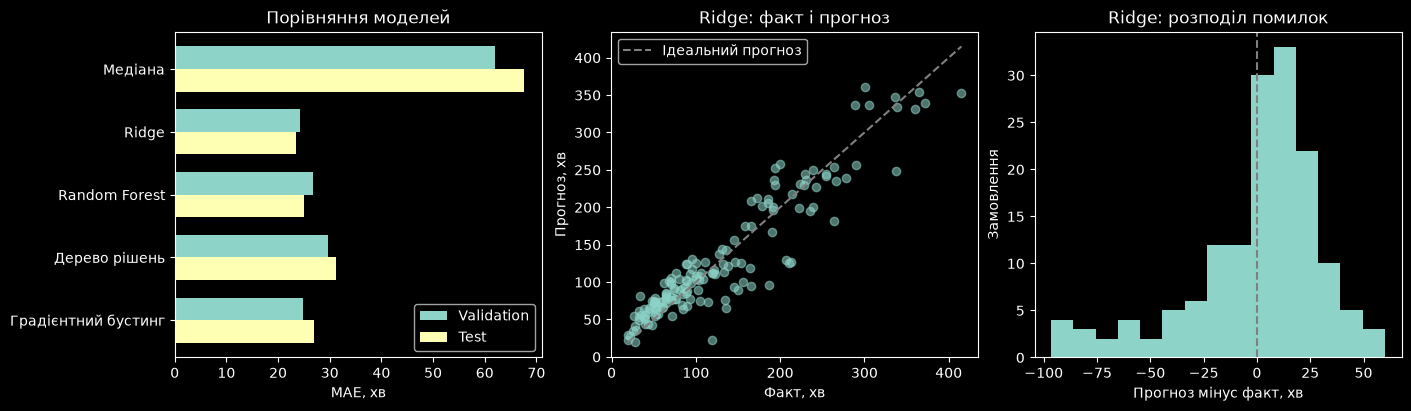

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout="constrained")
names = list(models)
x = np.arange(len(names))
axes[0].barh(x - 0.18, [best[n][1] for n in names], 0.36, label="Validation")
axes[0].barh(x + 0.18, [test_mae[n] for n in names], 0.36, label="Test")
axes[0].set(yticks=x, yticklabels=names, xlabel="MAE, хв", title="Порівняння моделей")
axes[0].invert_yaxis()
axes[0].legend()

pred = predictions[winner]
limits = [min(test_y.min(), pred.min()), max(test_y.max(), pred.max())]
axes[1].scatter(test_y, pred, alpha=0.55)
axes[1].plot(limits, limits, "--", color="gray", label="Ідеальний прогноз")
axes[1].set(xlabel="Факт, хв", ylabel="Прогноз, хв", title=f"{winner}: факт і прогноз")
axes[1].legend()

axes[2].hist(pred - test_y, bins=15)
axes[2].axvline(0, color="gray", linestyle="--")
axes[2].set(xlabel="Прогноз мінус факт, хв", ylabel="Замовлення", title=f"{winner}: розподіл помилок")
plt.show()

## 4. Перевірка за кількістю послуг
Дивись не лише на помилку, а й на кількість прикладів. Якщо в тесті немає замовлень із трьома послугами, оцінку для них на цьому наборі зробити не можна. Результати на синтетичних даних не підтверджують точність у реальному сервісі.

In [16]:
counts = np.array([row.features["service_count"] for row in test])
show_table(["Кількість послуг", "Замовлень у test", f"MAE {winner}, хв"], [
    (count, int(mask.sum()), f"{mean_absolute_error(test_y[mask], pred[mask]):.2f}" if mask.any() else "—")
    for count in sorted(set(counts) | {1, 2, 3})
    for mask in [counts == count]
])

| Кількість послуг | Замовлень у test | MAE Ridge, хв |
| --- | --- | --- |
| 1 | 121 | 22.64 |
| 2 | 32 | 26.24 |
| 3 | 0 | — |